# Soot Modeling Example

_This demo is part of Spitfire, with [licensing and copyright info here.](https://github.com/sandialabs/Spitfire/blob/master/license.md)_


_Highlights_

- Tabulating and plotting soot source term coefficients
- Tabulating and plotting soot radiation and absorption coefficients
- Tabulating and plotting gas radiation and absorption coefficients
- Integrating soot models along particle trajectories

In this demo, we build a nonadiabatic flamelet library then add coefficients relevant to soot modeling and absorption/radiation. The different model forms are shown in the soot modeling documentation. We then demonstrate how these libraries might be used for simulation with soot transport.



## The nonadiabatic flamelet library
First we'll build a flamelet library for an n-heptane/air system. We are using the liu-C7 mechanism, which limits the soot modeling to Aksit Moss since there is no benzene present. The higher fidelity caltech mechanism incorporates benzene, but takes longer to run.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
from scipy.interpolate import interp1d
from spitfire import build_nonadiabatic_defect_transient_slfm_library, ChemicalMechanismSpec, odesolve, PIController
from spitfire import get_soot_source_term_evaluator, tabulate_gas_radiation_model, tabulate_soot_radiation_model, tabulate_soot_source_coefficients
from spitfire.data.get import datafile
from spitfire.chemistry.analysis import get_ct_solution_array


In [2]:
mech = ChemicalMechanismSpec(cantera_input=datafile('liu-C7.yaml'), group_name='gas')
pressure = 101325.
air = mech.stream(stp_air=True)
air.TP = 300., pressure
fuel = mech.stream('TPY', (500., pressure, 'NXC7H16:1'))
flamelet_specs = {'mech_spec': mech,
                  'oxy_stream': air,
                  'fuel_stream': fuel,
                  'grid_points': 81}
chivals = np.logspace(-2,0,4)


In [3]:
lib = build_nonadiabatic_defect_transient_slfm_library(flamelet_specs, chivals)

----------------------------------------------------------------------------------
building nonadiabatic (defect) SLFM library
----------------------------------------------------------------------------------
- mechanism: /ascldap/users/earmstr/.conda/envs/spclone2/lib/python3.11/site-packages/spitfire/data/liu-C7.yaml
- 38 species, 105 reactions
- stoichiometric mixture fraction: 0.062
----------------------------------------------------------------------------------
----------------------------------------------------------------------------------
building adiabatic SLFM library
----------------------------------------------------------------------------------
- mechanism: cantera-input-not-given
- 38 species, 105 reactions
- stoichiometric mixture fraction: 0.062
----------------------------------------------------------------------------------
   1/   4 (chi_stoich =  1.0e-02 1/s)  converged in   3.07 s, T_max = 2234.0
   2/   4 (chi_stoich =  4.6e-02 1/s)  converged in   0.09 s, 

## Gas Radiation Model

Now we tabulate gas absorption (`gas_abs_coeff`) and radiation (`gas_rad_source`) coefficients. The absorption coefficient has units (1/m) and the radiation coefficient has units $(\mathrm{W}/\mathrm{m}^3)$.

The default model is `Barlow_GreyGas`, whose equations are outlined in the soot modeling documentation. Below we are plotting the coefficients over mixture fraction and all stoichiometric enthalpy defects for a single stoichiometric dissipation rate.

In [4]:
lib = tabulate_gas_radiation_model(mech, lib, modelname='Barlow_GreyGas')


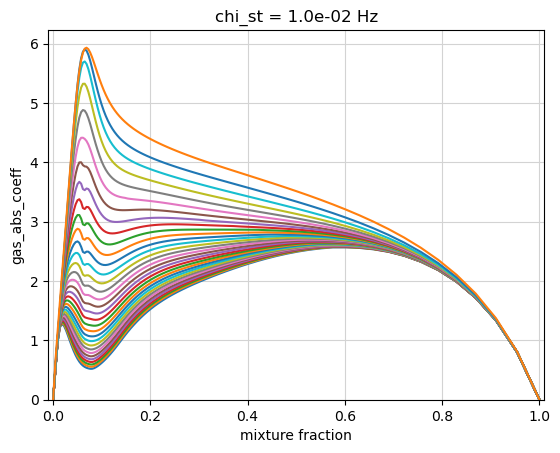

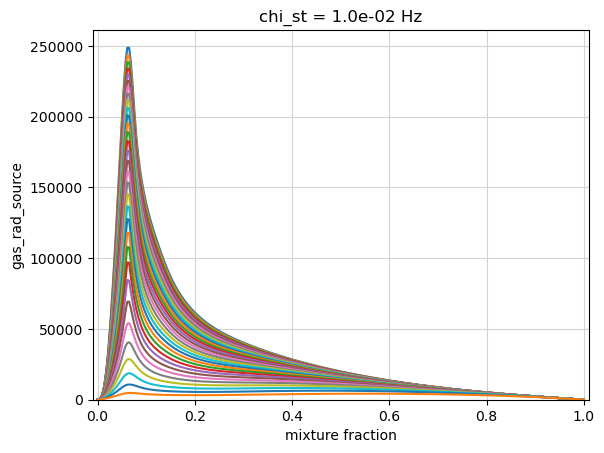

In [5]:
chi_index = 0
for prop in ['gas_abs_coeff','gas_rad_source']:
    plt.plot(lib.mixture_fraction_values, lib[prop][:,chi_index,:])
    plt.grid(color='lightgray')
    plt.ylabel(prop)
    plt.xlabel('mixture fraction')
    plt.title(f'chi_st = {lib.dissipation_rate_stoich_values[chi_index]:.1e} Hz')
    plt.xlim([-0.01,1.01])
    plt.ylim(bottom=0.)
    plt.show()


## Soot Radiation Model

Next we show how to tabulate soot absorption (`soot_abs_coeff`) and radiation (`soot_rad_source`) coefficients. The absorption coefficient has units (1/m) and the radiation coefficient has units $(\mathrm{W}/\mathrm{m}^3)$.

The default model is `linear_absorption_coefficient`, whose equations are outlined in the soot modeling documentation. This model takes parameters for the linear slope, intercept, and minimum value. Default parameter values are zero, which results in no radiation/absorption. We show suggested values below along with plots of the coefficients over mixture fraction and all stoichiometric enthalpy defects for a single stoichiometric dissipation rate.

In [6]:
lib = tabulate_soot_radiation_model(mech, lib, modelname='linear_absorption_coefficient', input_modelargs={'slope':1735., 'intercept':-3.75e5})


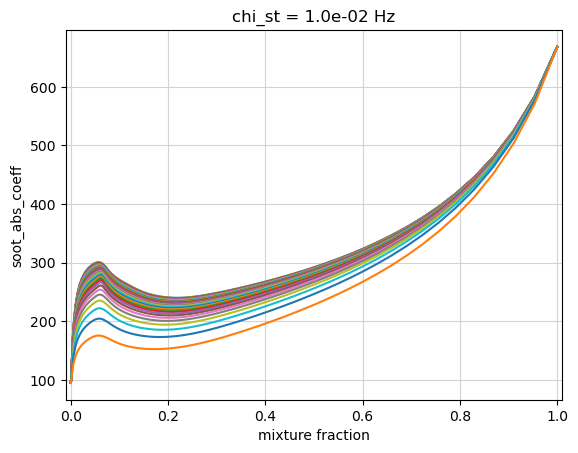

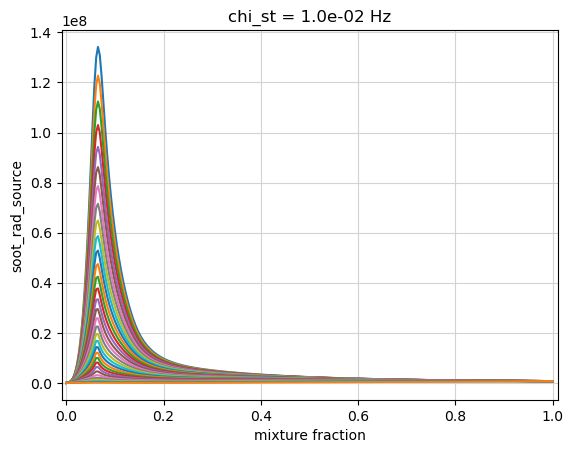

In [7]:
chi_index = 0
for prop in ['soot_abs_coeff','soot_rad_source']:
    plt.plot(lib.mixture_fraction_values, lib[prop][:,chi_index,:])
    plt.grid(color='lightgray')
    plt.ylabel(prop)
    plt.xlabel('mixture fraction')
    plt.title(f'chi_st = {lib.dissipation_rate_stoich_values[chi_index]:.1e} Hz')
    plt.xlim([-0.01,1.01])
    plt.show()


## Soot Source Coefficient Model

Supported soot models include: `Aksit_Moss`, `Aksit_Moss_Benzene`, and `PAH_alpha`. The mechanism we used for this demo does not have benzene, so we will stick with `Aksit_Moss`. All model equations are shown in the soot documentation.

Running `tabulate_soot_source_coefficients` adds relevant coefficients for nucleation, coagulation, condensation, surface growth, and surface oxidation to the library. You can also specify a `soot_leakage_fraction` which controls the amount of soot allowed to "leak" into fuel-lean regions of the flame, accounting for finite-rate oxidation. This is based on a sub-filter model for soot oxidation, where 0% leakage corresponds to infinitely fast oxidation (not allowing soot to be present near the oxidizer stream) and larger leakage rates limit that oxidation. Using 0.>=`soot_leakage_fraction`>1. adds a 'soot_subfilter' property to the library, showing the function with which the surface growth and oxidation terms get multiplied.

Below we compare the 'Aksit_Moss' coefficients with 100% and 1% soot leakage. Nucleation and coagulation are identical between the two libraries. The surface growth and oxidation coefficients have been modified for the smaller leakage, seen more dramatically in the oxidation coefficients. The 1% leakage limits the amount of soot present for lean mixtures, assuming it gets oxidized faster than the original library. Therefore, the oxidation coefficients for the 1% leakage library are smaller in those lean regions compared to the original 100% leakage library.

Units are as follows:

- surface growth and oxidation ('surf_'): $\mathrm{kg}^{4/3} \mathrm{m}^{-3} \mathrm{s}^{-1} \mathrm{kmol}^{-1/3}$

- nucleation ('nucl_'): $\mathrm{kmol}^{1} \mathrm{m}^{-3} \mathrm{s}^{-1}$

- coagulation ('coag'): $\mathrm{kg}^{11/6} \mathrm{m}^{-3} \mathrm{s}^{-1} \mathrm{kmol}^{-5/6}$


In [8]:
soot_model = 'Aksit_Moss'
lib_p0 = tabulate_soot_source_coefficients(mech, lib, soot_model)
lib_p1 = tabulate_soot_source_coefficients(mech, lib, soot_model, soot_leakage_fraction=0.01)


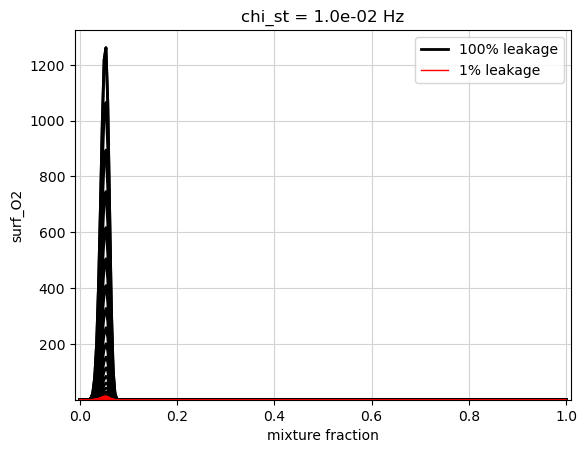

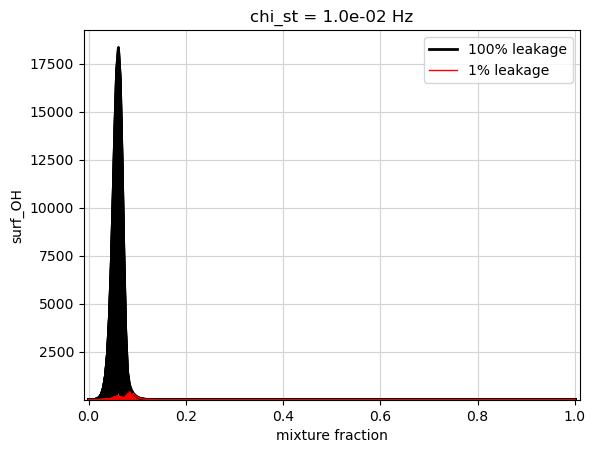

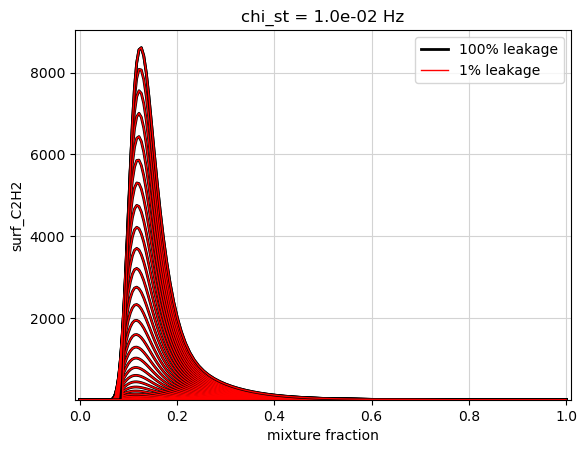

In [9]:
logscale = False
chi_index = 0

colors = ['k','r']
for prop in ['surf_O2', 'surf_OH', 'surf_C2H2']:
    lp0 = lib_p0[prop][:,chi_index,:]
    lp1 = lib_p1[prop][:,chi_index,:]

    plt.plot(lib_p0.mixture_fraction_values, lp0, '-', color=colors[0], linewidth=2)
    plt.plot(lib_p1.mixture_fraction_values, lp1, '-', color=colors[1], linewidth=1)
    #for legend...
    plt.plot(lib_p0.mixture_fraction_values, lp0[:,0], '-', color=colors[0], linewidth=2, label='100% leakage')
    plt.plot(lib_p1.mixture_fraction_values, lp1[:,0], '-', color=colors[1], linewidth=1, label=f'1% leakage')

    plt.grid(color='lightgray')
    if logscale:
        plt.yscale('log')
    plt.ylim(bottom=1.e-4)
    plt.title(f'chi_st = {lib.dissipation_rate_stoich_values[chi_index]:.1e} Hz')
    plt.xlim([-0.01,1.01])
    plt.ylabel(prop)
    plt.xlabel('mixture fraction')
    plt.legend()
    plt.show()


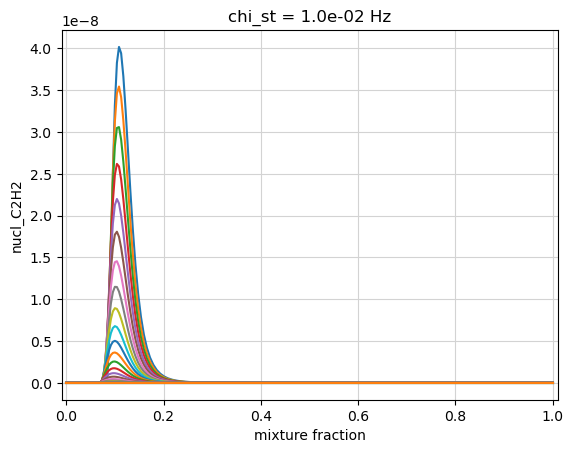

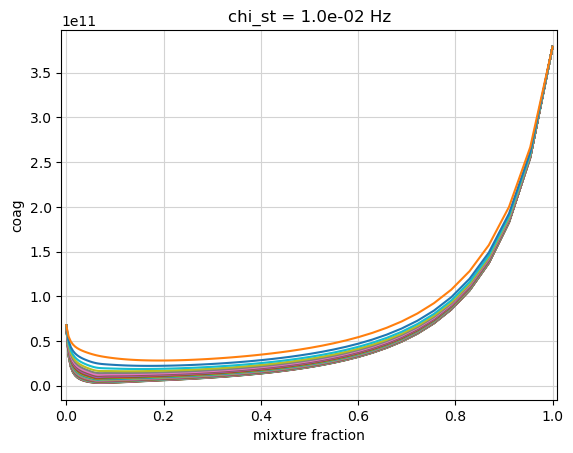

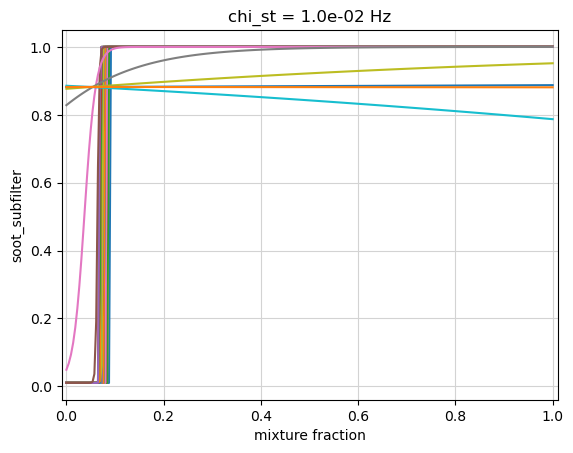

In [10]:
chi_index = 0
for prop in ['nucl_C2H2','coag','soot_subfilter']:
    plt.plot(lib_p1.mixture_fraction_values, lib_p1[prop][:,chi_index,:])
    plt.grid(color='lightgray')
    plt.ylabel(prop)
    plt.xlabel('mixture fraction')
    plt.title(f'chi_st = {lib_p1.dissipation_rate_stoich_values[chi_index]:.1e} Hz')
    plt.xlim([-0.01,1.01])
    plt.show()


## Evaluating Soot Source Terms

Once we have tabulated all relevant soot and radiation coefficients, our library is ready to use in simulation for a sooting fire that transports a soot mass fraction (unitless) and soot number density (kmol soot / kg air). We can compose source terms given the current mass fraction, number density, and tabulated coefficients following the equations in our soot documentation. The `get_soot_source_term_evaluator` function will detect which soot model was used to generate a library based on the species/coefficients present and return the appropriate function for evaluating the source terms for soot mass fraction and soot number density. If verbose is True, the soot model detected on the library will be printed. Below, we find the "aksit-moss" model and save off the appropriate `soot_src_aksit_moss` function.

When evaluated, the source term function will return a dictionary of the source terms for the soot number density ('S_Ns') and soot mass fraction ('S_Ys') along with various contributions to those source terms. The 'input_mult_dict' argument can be used to set multipliers for any of the source term coefficients on a library. For example, passing {'c2h2':2} will double the surface growth coefficient for acetylene before evaluating the source terms. More details on the supported soot_src_... functions can be found in the documentation.


In [11]:
src_eval = get_soot_source_term_evaluator(lib_p0)
src_eval


Detected soot model "aksit-moss" in the table.


<function spitfire.chemistry.soot.soot_src_aksit_moss(soot_number_density, soot_mass_fraction, nucl_C2H2, coag, surf_C2H2, surf_O2, surf_OH, input_mult_dict=None)>

In order to demonstrate the source term model in action, we load some particle trajectories over which to transport soot. The ex_particle_data.pkl file has three particle trajectories from RANS of a 2m-diameter sooting pool fire. The two soot equations were transported in this simulation, and the result is shown below over each particle's residence time. This gives an idea of the soot observed over each particle trajectory. However, these data were generated with a different fuel composition and chemical mechanism. We are mainly interested in the flamelet inputs (mixture fraction, stoichiometric dissipation rate, and stoichiometric enthalpy defect) observed along these trajectories, which we also plot, along with the height of the particles, over their residence times below. These particles also have a scaled scalar variance, but we will ignore this flamelet dimension to simplify the demo. It could be added back in if we convolved our libraries over a mixture fraction presumed PDF using `apply_mixing_model`. These data provide realistic particle pathways for us to use in comparing different soot models a priori.

Using a Lagrangian reference for each of the particles as they travel along their trajectories, we can define the following ODEs for soot production due to reaction alone

$\frac{\mathrm{d}N_s}{\mathrm{d}t} = \dot{S_{N_s}}/\rho$

$\frac{\mathrm{d}Y_s}{\mathrm{d}t} = \dot{S_{Y_s}}/\rho$

and integrate them along those trajectories in order to estimate soot levels from different libraries. We will be comparing soot levels from using the 100% and 1% soot leakage models with Aksit-Moss, where we expect the 1% soot leakage to produce more soot since oxidation is more limited. We would expect higher soot levels when including the effects of benzene, but that would require using a different mechanism as mentioned at the start of the demo.

This analysis ignores the effects of diffusion with and without turbulence, which become more important near edges of the flame. Therefore, we can't expect accurate estimates from reaction alone in those regions, especially as the particles travel higher in the flames. We will focus on maximum and average soot values around heights of 2.5 times the pool diameter of 2 meters.


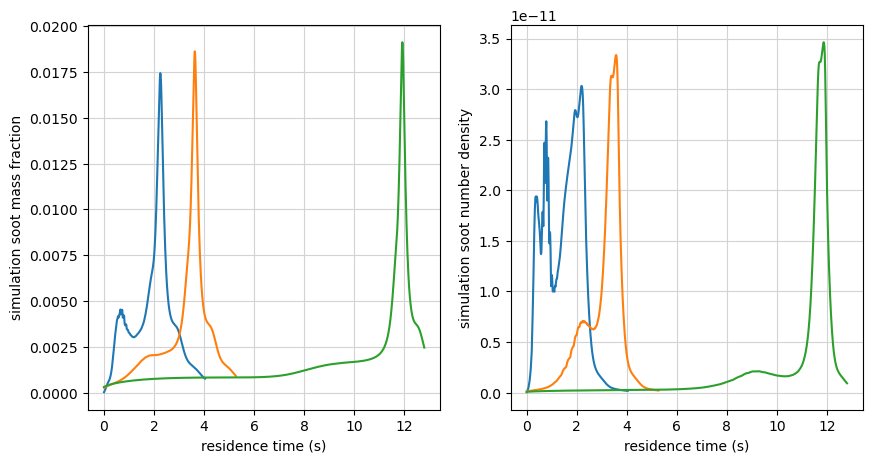

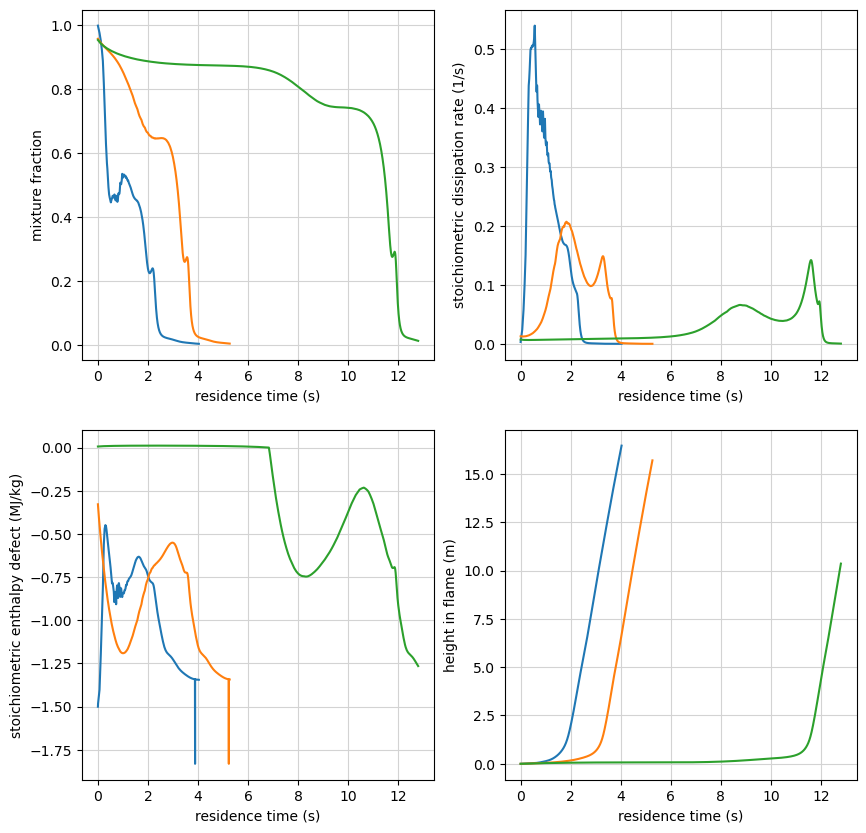

In [12]:
### loading particle data
with open(f'ex_particle_data.pkl', 'rb') as handle:
    particle_data = pickle.load(handle)

fig, ax = plt.subplots(1,2, figsize=(10,5))
for it in particle_data:
    ax[0].plot(particle_data[it]['residence_time'], particle_data[it]['sim_Ys'])
    ax[1].plot(particle_data[it]['residence_time'], particle_data[it]['sim_Ns'])
ax[0].set_ylabel('simulation soot mass fraction')
ax[1].set_ylabel('simulation soot number density')
for a in ax:
    a.set_xlabel('residence time (s)')
    a.grid(color='lightgray')
plt.show()

fig, ax = plt.subplots(2,2, figsize=(10,10))
for it in particle_data:
    ax[0,0].plot(particle_data[it]['residence_time'], particle_data[it]['z'])
    ax[0,1].plot(particle_data[it]['residence_time'], particle_data[it]['xst'])
    ax[1,0].plot(particle_data[it]['residence_time'], particle_data[it]['gst']/1.e6)
    ax[1,1].plot(particle_data[it]['residence_time'], particle_data[it]['height'])
ax[0,0].set_ylabel('mixture fraction')
ax[0,1].set_ylabel('stoichiometric dissipation rate (1/s)')
ax[1,0].set_ylabel('stoichiometric enthalpy defect (MJ/kg)')
ax[1,1].set_ylabel('height in flame (m)')
for a in ax.ravel():
    a.set_xlabel('residence time (s)')
    a.grid(color='lightgray')
plt.show()


We first add density onto each of the libraries, which is needed in the soot ODEs.

In [13]:
ctsol0, lib_shape0 = get_ct_solution_array(mech, lib_p0)
lib_p0['density'] = ctsol0.density_mass.reshape(lib_shape0)

ctsol1, lib_shape1 = get_ct_solution_array(mech, lib_p1)
lib_p1['density'] = ctsol1.density_mass.reshape(lib_shape1)


Then we interpolate all of the library properties over the flamelet inputs. This allows us to evaluate the libraries at arbitrary flamelet parameters during integration. The cell below requires the ``pytabprops`` library to be installed. 

In [14]:
from pytabprops import LagrangeInterpolant3D, StateTable

def table_interp(lib_to_tab):
    tbl = StateTable()
    for prop in lib_to_tab.props:
        interp = LagrangeInterpolant3D(3,
                                    lib_to_tab.mixture_fraction_values,
                                    lib_to_tab.dissipation_rate_stoich_values,
                                    np.abs(lib_to_tab.enthalpy_defect_stoich_values),
                                    lib_to_tab[prop].ravel(order='F'), 
                                    True)
        tbl.add_entry(prop, interp, ['z','chi','gamma'])
        # checking the reconstruction...
        pred = tbl.query(prop,
                lib_to_tab.mixture_fraction_grid,
                lib_to_tab.dissipation_rate_stoich_grid,
                np.abs(lib_to_tab.enthalpy_defect_stoich_grid))
        err = np.max(np.abs(pred - lib_to_tab[prop]))
        if err>1.e-16:
            print(f'failed reconstruction for {prop} with error {err:.2e}')
    return tbl

tbl_p0 = table_interp(lib_p0)
tbl_p1 = table_interp(lib_p1)


Now we can use Spitfire's `odesolve` to integrate the two ODEs. This expects a source term function to take in time and the current state, which we define below as `ode_src`. This function evaluates the flamelet parameters given the current time, then uses those to query our interpolated coefficients and density. We can then return the source terms evaluated with our saved function `src_eval`. We initialize the state to very small soot levels, but this can also be played with depending on the initial placement in the flame.


In [15]:
def particle_interpolants(particle_idx):
    residence_time = particle_data[particle_idx]['residence_time']
    z   = particle_data[particle_idx]['z']
    xst = particle_data[particle_idx]['xst']
    gst = particle_data[particle_idx]['gst']

    z_interp   = interp1d(residence_time, z,           kind='linear')
    xst_interp = interp1d(residence_time, xst,         kind='linear')
    gst_interp = interp1d(residence_time, np.abs(gst), kind='linear')
    return z_interp, xst_interp, gst_interp

def particle_integrals(tbl):
    integral_dict = {}
    for ip in particle_data:
        integral_dict[ip] = {}
        residence_time = particle_data[ip]['residence_time']
        z_interp, xst_interp, gst_interp = particle_interpolants(ip)

        def ode_src(t, NsYs):
            z = z_interp(t)
            x_st = xst_interp(t)
            g_st = gst_interp(t)
            inputs = [z, x_st, g_st]

            rho = tbl.query('density', *inputs)
            nucl_C2H2 = tbl.query('nucl_C2H2', *inputs)
            coag = tbl.query('coag', *inputs)
            surf_C2H2 = tbl.query('surf_C2H2', *inputs)
            surf_O2 = tbl.query('surf_O2', *inputs)
            surf_OH = tbl.query('surf_OH', *inputs)

            soot_number_density = np.min([np.max([NsYs[0], 1.e-16]), 1.e6])
            soot_mass_fraction  = np.min([np.max([NsYs[1], 1.e-16]), 1.])
            
            srcs = src_eval(soot_number_density, soot_mass_fraction, nucl_C2H2, coag, surf_C2H2, surf_O2, surf_OH)
            return np.array([srcs['S_Ns'], srcs['S_Ys']])/rho

        init = 1.e-16*np.ones(2,)
        ts, NsYs = odesolve(ode_src, init, save_each_step=True, stop_at_time=residence_time.max(),
                            step_size=PIController(target_error=1.e-10, first_step=1.e-3, max_step=2.5e-2))
        integral_dict[ip]['t'] = ts
        integral_dict[ip]['Ns'] = NsYs[:,0]
        integral_dict[ip]['Ys'] = NsYs[:,1]
    return integral_dict

integrals_p0 = particle_integrals(tbl_p0)
integrals_p1 = particle_integrals(tbl_p1)


Below we plot the results for soot mass fraction and number density for each of the soot models. The peak soot values for both models are actually very similar, with the 1% leakage being slightly larger. The main difference is the behavior after hitting peak production, where the larger oxidation from 100% leakage pulls soot down to essentially zero while 1% leakage maintains a larger level. However, after the peak production, the particles start to rise higher in the flame, where we would expect diffusion to pull down those soot levels even more (similar to the trends seen above in the simulation soot profiles).


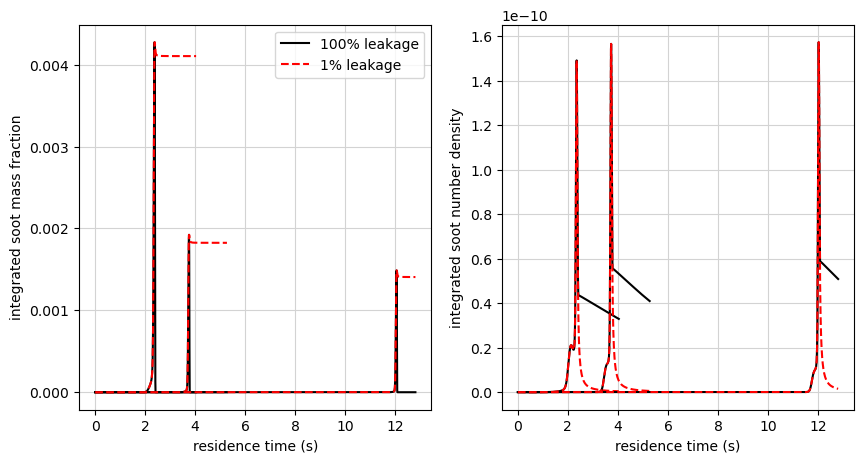

In [16]:
fig, ax = plt.subplots(1,2, figsize=(10,5))
for it in integrals_p0:
    ax[0].plot(integrals_p0[it]['t'], integrals_p0[it]['Ys'], 'k-', label='100% leakage' if it==0 else None)
    ax[1].plot(integrals_p0[it]['t'], integrals_p0[it]['Ns'], 'k-')
    ax[0].plot(integrals_p1[it]['t'], integrals_p1[it]['Ys'], 'r--', label='1% leakage' if it==0 else None)
    ax[1].plot(integrals_p1[it]['t'], integrals_p1[it]['Ns'], 'r--')
ax[0].set_ylabel('integrated soot mass fraction')
ax[1].set_ylabel('integrated soot number density')
ax[0].legend()
for a in ax:
    a.set_xlabel('residence time (s)')
    a.grid(color='lightgray')
plt.show()


The soot volume fraction is another useful quantity to analyze. This can be calculated from

$f_v = Y_s \rho / \rho_s$

where the density of soot $\rho_s = 1800 \ \mathrm{kg}/\mathrm{m}^3$. The 1% leakage model reaches higher levels as expected.


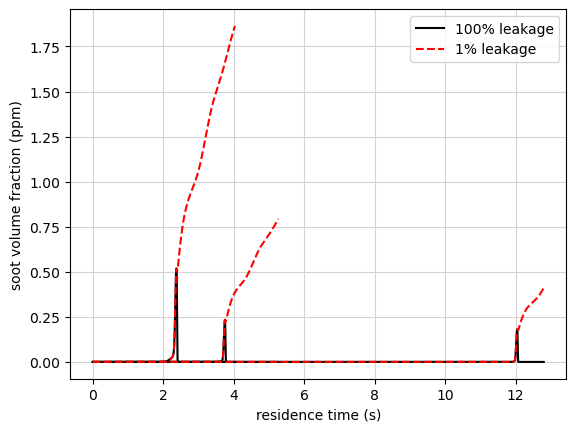

In [17]:
for it in integrals_p0:
    z_interp, xst_interp, gst_interp = particle_interpolants(it)

    ts_p0 = integrals_p0[it]['t']
    z_p0 = z_interp(ts_p0)
    x_st_p0 = xst_interp(ts_p0)
    g_st_p0 = gst_interp(ts_p0)
    inputs_p0 = [z_p0, x_st_p0, g_st_p0]

    ts_p1 = integrals_p1[it]['t']
    z_p1 = z_interp(ts_p1)
    x_st_p1 = xst_interp(ts_p1)
    g_st_p1 = gst_interp(ts_p1)
    inputs_p1 = [z_p1, x_st_p1, g_st_p1]

    rho_p0 = tbl_p0.query('density', *inputs_p0)
    rho_p1 = tbl_p1.query('density', *inputs_p1)
    fv_ppm_p0 = integrals_p0[it]['Ys'] * rho_p0 / 1800. * 1.e6
    fv_ppm_p1 = integrals_p1[it]['Ys'] * rho_p1 / 1800. * 1.e6

    plt.plot(ts_p0, fv_ppm_p0,'k-', label='100% leakage' if it==0 else None)
    plt.plot(ts_p1, fv_ppm_p1,'r--', label='1% leakage' if it==0 else None)
plt.xlabel('residence time (s)')
plt.ylabel('soot volume fraction (ppm)')
plt.legend()
plt.grid(color='lightgray')
plt.show()


Finally we plot the average soot mass fraction of each model for different heights in the flame over mixture fraction. Heights are documented as factors of the pool diameter D = 2m. Below 2.25D, soot levels are low and there is little difference between the models. The largest difference happens between 2.25D and 2.5D where the 1% leakage model produces almost twice as much soot on average than the 100% leakage model, especially at smaller mixture fraction where oxidation is taking place. As we continue higher in the flame, the soot levels for the 1% leakage model flatten out, which is where we expect diffusion to become more important and reduce those levels in reality.

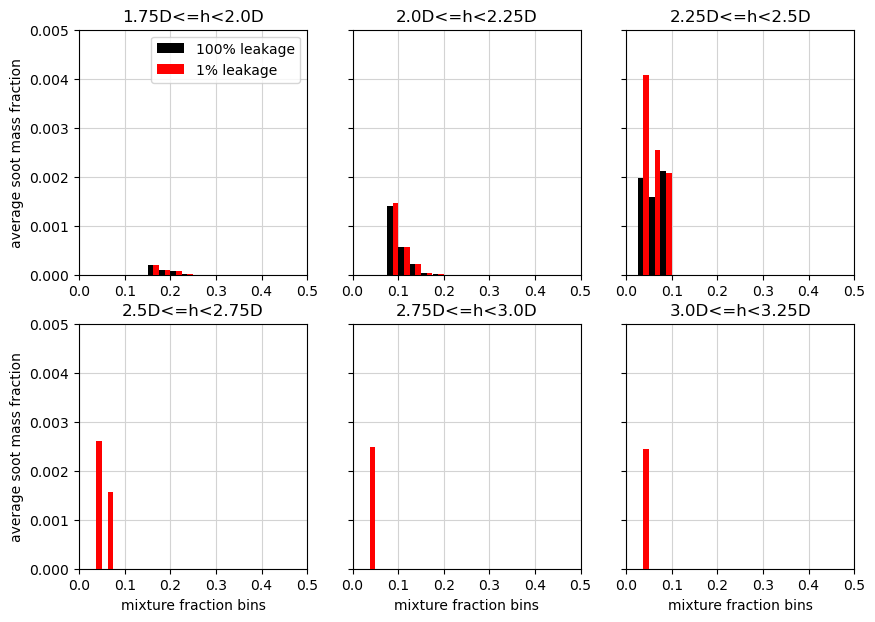

In [18]:
D = 2. # 2m diameter

zbins = np.linspace(0.,0.5,21)
Dbins = np.linspace(1.75,3.25,7)

zspace = zbins[1] - zbins[0]
zcenters = zbins[:-1] + 0.5*zspace

fig, axs = plt.subplots(2,3, figsize=(10,7), sharey=True)
for id in range(Dbins.size-1):
    Ysums_p0 = np.zeros(zbins.size-1)
    Ycount_p0 = np.zeros(zbins.size-1)
    Ysums_p1 = np.zeros(zbins.size-1)
    Ycount_p1 = np.zeros(zbins.size-1)
    for ip in integrals_p0:
        h = particle_data[ip]['height']
        Z = particle_data[ip]['z']
        t = particle_data[ip]['residence_time']
        Z_interp = interp1d(t, Z, kind='linear')
        h_interp = interp1d(t, h, kind='linear')

        t_p0 = integrals_p0[ip]['t']
        Z_p0 = Z_interp(t_p0)
        h_p0 = h_interp(t_p0)
        Ys_p0 = integrals_p0[ip]['Ys']
        hidx_p0 = np.argwhere((Dbins[id]*D<=h_p0)&(h_p0<Dbins[id+1]*D))
        Z_p0 = Z_p0[hidx_p0]
        Ys_p0 = Ys_p0[hidx_p0]

        t_p1 = integrals_p1[ip]['t']
        Z_p1 = Z_interp(t_p1)
        h_p1 = h_interp(t_p1)
        Ys_p1 = integrals_p1[ip]['Ys']
        hidx_p1 = np.argwhere((Dbins[id]*D<=h_p1)&(h_p1<Dbins[id+1]*D))
        Z_p1 = Z_p1[hidx_p1]
        Ys_p1 = Ys_p1[hidx_p1]

        for iz in range(zbins.size-1):
            zidx_p0 = np.argwhere((Z_p0>=zbins[iz])&(Z_p0<zbins[iz+1]))
            Ysums_p0[iz] += np.sum(Ys_p0[zidx_p0])
            Ycount_p0[iz] += Ys_p0[zidx_p0].size

            zidx_p1 = np.argwhere((Z_p1>=zbins[iz])&(Z_p1<zbins[iz+1]))
            Ysums_p1[iz] += np.sum(Ys_p1[zidx_p1])
            Ycount_p1[iz] += Ys_p1[zidx_p1].size

    Yavg_p0 = Ysums_p0/(Ycount_p0+1.e-16)
    Yavg_p1 = Ysums_p1/(Ycount_p1+1.e-16)

    axs.ravel()[id].bar(zcenters-zspace/4., Yavg_p0, width=zspace*0.49,color='k',zorder=10, label='100% leakage')
    axs.ravel()[id].bar(zcenters+zspace/4., Yavg_p1, width=zspace*0.49,color='r',zorder=10, label='1% leakage')
    axs.ravel()[id].grid(True, color='lightgray')
    axs.ravel()[id].set_xlim([zbins.min(), zbins.max()])
    axs.ravel()[id].set_title(f'{Dbins[id]}D<=h<{Dbins[id+1]}D')
    axs.ravel()[id].set_ylim([0.,0.005])
for id in [0,3]:
    axs.ravel()[id].set_ylabel("average soot mass fraction")
for id in [3,4,5]:
    axs.ravel()[id].set_xlabel('mixture fraction bins')
axs.ravel()[0].legend()
plt.show()
